# Post-buckling of an axially compressed cylinder: Simo, Fox and Rifai (1990)

J. C. Simo, D. D. Fox and M. S. Rifai, *On a stress resultant geometrically exact shell model. Part III: Computational aspects of the nonlinear theory*, Computer Methods in Applied Mechanics and Engineering 79 (1990) 21-70, Section 6.3.4, "Post-buckling analysis of a simply-supported cylinder; effect of initial imperfections", pp. 54-57, Fig. 6.3.4 on p. 56, with the results of G. M. Stanley, *Continuum-based shell elements*, PhD dissertation, Stanford University, 1985 (9-ANS elements).

A cylinder of radius $R = 36$, length $L = 100$, thickness $t = 0.125$, $E = 10^7$, $\nu = 0.3$ (consistent units) under axial compression, traced deep into the post-buckled regime by the Riks method of `structsolve`:

- Fig. 6.3.4 (a): imperfections of 10 % and 50 % of $t$ in the shape of the lowest linear buckling mode, load against the maximum axial deflection of the loaded edge, with Stanley's points;
- Fig. 6.3.4 (c): the same with the average axial deflection;
- Fig. 6.3.4 (d): the perfect cylinder, traced by branch switching (`Analysis.branch_switching` with `inertia = True`), with `linear_solver = 'pardiso'` and `'splu'`.

The loads are normalized by the linear buckling load. The values of the figure were read on the page rendered at 300 dpi with a grid drawn over the axes, with a precision of about $\pm 0.0003$ in the deflection and $\pm 0.01$ in the load; they are in `tests/simo1990_utils.py`, with the model. The model is a shell of [`panels`](https://github.com/saullocastro/panels) 0.15.0, which is not a dependency of `structsolve`: run the notebook from this folder with `panels` and oneMKL (`pip install mkl`, for `linear_solver='pardiso'`) installed. The analyses run again at each execution, in about 6 min on one thread (`MKL_NUM_THREADS=1`). The convergence in the Ritz terms ($8 \times 8$ to $14 \times 14$) is in [Post-buckling of an axially compressed cylinder](ex_cylinder_postbuckling.ipynb), computed with the command line of `tests/simo1990_utils.py`; `tests/test_simo1990_cylinder.py` checks the imperfection, the 50 % imperfection and the perfect cylinder with both linear solvers.

In [1]:
%matplotlib inline
import numpy as np
import matplotlib.pyplot as plt
from IPython.display import Markdown, display

import os
import sys

import panels

# the model of the cylinder is shared with the tests
sys.path.insert(0, os.path.join('..', 'tests'))
import simo1990_utils as su

print('panels', panels.__version__)


def markdown_table(header, rows):
    lines = ['| ' + ' | '.join(header) + ' |', '|' + '---|'*len(header)]
    lines += ['| ' + ' | '.join(row) + ' |' for row in rows]
    return Markdown('\n'.join(lines))

panels 0.15.0


## The model

As in Simo et al. and Stanley, an $L/10 \times 15°$ section is modelled, with symmetry conditions on the interior edges and a simple support on the loaded edge: the lowest buckling mode is then the diamond mode of 5 axial half-waves and 12 circumferential waves, of which the section spans a quarter of an axial wave and half a circumferential one. It is one `panels.shell.Shell` of the model `cylshell_clpt_donnell` (Donnell kinematics, classical laminated plate theory), $a = L/10$ along the axis $x$ and $b = R \pi/12$ along the arc $y$, with $8 \times 8$ Bardell terms (the limit loads change by less than 0.003 from $8 \times 8$ to $14 \times 14$ terms), and the flags of Bardell's functions (`0` removes the value, `r` its normal derivative):

| Edge | Condition | Flags |
|---|---|---|
| $x = 0$, loaded | simple support, $v = w = 0$ | `x1v = x1w = 0`, the others `1` |
| $x = a$ | symmetry, $u = v_{,x} = w_{,x} = 0$ | `x2u = x2vr = x2wr = 0` |
| $y = 0$, $y = b$ | symmetry, $u_{,y} = v = w_{,y} = 0$ | `y1ur = y1v = y1wr = 0`, same for `y2` |

The axial load $N_{cl} = E t^2/(R\sqrt{3(1-\nu^2)})$ per unit length is applied at $x = 0$ with `add_distr_load_fixed_x`, scaled by the lowest load multiplier of the linear buckling analysis `structsolve.lb`, such that the load factor of the non-linear analyses is the load normalized by the linear buckling load. The callables `calc_fext`, `calc_fint`, `calc_kC` and `calc_kG` of the shell are those passed to `structsolve.Analysis`.

8 x 8 terms, 192 degrees of freedom
linear buckling load: 1.00472 N_cl, N_cl = 2626.9


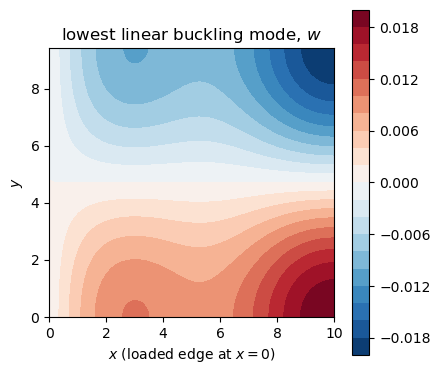

In [2]:
M = N = 8
s, lbd_cr, mode = su.normalized_shell(M, N)
print('%d x %d terms, %d degrees of freedom' % (M, N, s.get_size()))
print('linear buckling load: %.5f N_cl, N_cl = %.1f' % (lbd_cr, su.N_CL))
fig, ax = plt.subplots(figsize=(4.5, 4))
s.uvw(mode, gridx=60, gridy=60)
cf = ax.contourf(s.plot_mesh['Xs'], s.plot_mesh['Ys'], s.fields['w'], levels=21, cmap='RdBu_r')
ax.set_aspect('equal')
ax.set_xlabel('$x$ (loaded edge at $x = 0$)')
ax.set_ylabel('$y$')
ax.set_title('lowest linear buckling mode, $w$')
plt.colorbar(cf)
plt.tight_layout()
plt.show()

## The initial imperfection

Neither `panels` nor `structsolve` takes a geometric imperfection. For the Donnell kinematics it is added exactly: with the Ritz vector $\boldsymbol{c}_0$ of the imperfection $w_0$ (the $w$ part of the mode, $u = v = 0$, scaled to $\max|w_0| = \xi t$), the membrane strains of the imperfect shell, e.g. $\varepsilon_{xx} = u_{,x} + \frac{1}{2} w_{,x}^2 + w_{0,x} w_{,x}$, and its curvatures are the differences $\boldsymbol{\varepsilon}(\boldsymbol{c} + \boldsymbol{c}_0) - \boldsymbol{\varepsilon}(\boldsymbol{c}_0)$ of the strains of the perfect shell, the non-linear terms being quadratic in $w$. With $\boldsymbol{B}(\boldsymbol{c}) = \partial\boldsymbol{\varepsilon}/\partial\boldsymbol{c}$, affine in $\boldsymbol{c}$, and the resultants $\boldsymbol{N}_0$ of the state $\boldsymbol{c}_0$, linear and non-linear parts,

$$\boldsymbol{F}_{int,imp}(\boldsymbol{c}) = \int \boldsymbol{B}(\boldsymbol{c} + \boldsymbol{c}_0)^\top (\boldsymbol{N}(\boldsymbol{c} + \boldsymbol{c}_0) - \boldsymbol{N}_0)\, dA = \boldsymbol{F}_{int}(\boldsymbol{c} + \boldsymbol{c}_0) - \boldsymbol{F}_{int}(\boldsymbol{c}_0) - \boldsymbol{K}_G(\boldsymbol{N}_0) \boldsymbol{c}$$

$$\boldsymbol{K}_{T,imp}(\boldsymbol{c}) = \boldsymbol{K}_T(\boldsymbol{c} + \boldsymbol{c}_0) - \boldsymbol{K}_G(\boldsymbol{N}_0)$$

with $\boldsymbol{F}_{int,imp}(\boldsymbol{0}) = \boldsymbol{0}$: the imperfect shell is unstressed at $\boldsymbol{c} = \boldsymbol{0}$. `Shell.calc_kG(c=c0)` cannot give $\boldsymbol{K}_G(\boldsymbol{N}_0)$: it has the resultants of the linear part of the strains only, and `su.calc_kG_N` integrates $\boldsymbol{K}_G(\boldsymbol{N}_0)$ at the Gauss points of the shell. `su.ImperfectShell` gives the callables of `structsolve.Analysis`.

The checks of `su.verify`, for $8 \times 8$ terms and $\xi = 0.5$, at a random state with $\max|w| = 0.3 t$: the geometric stiffness matrix with the linear resultants is `calc_kG(c)` of `panels`, which has no non-linear resultants; the internal forces vanish at $\boldsymbol{c} = \boldsymbol{0}$; the tangent stiffness matrix is the derivative of the internal forces (central differences); independently of the formula above, the internal forces are the gradient of the strain energy $\frac{1}{2}\int \boldsymbol{\varepsilon}_{imp}^\top \boldsymbol{ABD}\, \boldsymbol{\varepsilon}_{imp}\, dA$ integrated from `Shell.strain` of $\boldsymbol{c} + \boldsymbol{c}_0$ and $\boldsymbol{c}_0$, with an error of second order in $h$, which fails with `calc_kG(c0)` in place of $\boldsymbol{K}_G(\boldsymbol{N}_0)$; and without imperfection the model is the perfect one.

In [3]:
su.verify(M, N, xi=0.5)

kG(N_L(c)), this script vs. panels calc_kG(c): rel. diff 8.24e-16
kG(N(c)) vs. calc_kG(c): rel. diff 1.82e-03 (non-linear stresses missing in calc_kG)


|fint_imp(0)| / |fint(c0)| = 0.00e+00
h=1e-04 |(f(c+hv)-f(c-hv))/2h - kT_imp v|/|kT_imp v| = 5.26e-12
h=1e-05 |(f(c+hv)-f(c-hv))/2h - kT_imp v|/|kT_imp v| = 5.01e-14
h=1e-06 |(f(c+hv)-f(c-hv))/2h - kT_imp v|/|kT_imp v| = 4.20e-13


h=1e-04 (U(c+hv)-U(c-hv))/2h vs fint_imp(c).v: rel. diff 1.72e-08
h=1e-05 (U(c+hv)-U(c-hv))/2h vs fint_imp(c).v: rel. diff 1.71e-10
same with calc_kG(c0) in place of kG(N0): rel. diff 7.48e-05


xi=0: |fint_imp(c) - fint(c)|/|fint(c)| = 0.00e+00


## Riks analyses

`su.run_riks` creates the `structsolve.Analysis` with `NL_method = 'arc_length_riks'`, `final_load_factor = None`, `initialInc = maxInc = 0.1`, `minInc = 1e-5` and the stop criterion `structsolve.stopping.value_reached` of the maximum axial deflection of the loaded edge, here 0.04, about twice the deflection at the linear buckling load; the other attributes are at their defaults, e.g. Crisfield's convergence criterion with `relTOL = 1e-9`. The residual of every converged increment is checked afterwards.

The perfect cylinder runs with `inertia = True`, `branch_switching = 1`, `initialInc = maxInc = 0.03` and the unknowns scaled to a unit diagonal of the linear stiffness matrix (`su.ScaledModel`, which changes only the coordinates of the Ritz vector, such that the eigenvalues of the tangent closest to zero are those of the physical instabilities rather than of weakly stiff Ritz terms). A bifurcation is detected by the count of negative eigenvalues of the factorization with `linear_solver = 'pardiso'` and by the sign of the determinant with `'splu'`; the next step starts along the critical eigenvector, computed by a subspace iteration with the available factorization, and is corrected with the spherical constraint.

In [4]:
res = {}
runs = (('10 %', 0.1, {}),
        ('50 %', 0.5, {}),
        ('perfect, pardiso', 0., dict(branch_switching=1, linear_solver='pardiso')),
        ('perfect, splu', 0., dict(branch_switching=1, linear_solver='splu')))
for key, xi, kwargs in runs:
    r = su.run_riks(xi, M, N, umax=0.04, silent=True, save=False, verbose=False, **kwargs)
    r['u_avg'] = np.concatenate(([0.], r['u'][:, 0]))
    r['u_max'] = np.concatenate(([0.], r['u'][:, 1]))
    r['lbds0'] = np.concatenate(([0.], r['lbds']))
    res[key] = r
    print('%-17s %4d increments, %5.1f s, max. relative residual %.1e, max|w|/t at the end %.1f'
          % (key, len(r['lbds']), r['elapsed'], r['max_residual'], r['wmax'][-1]/su.t))
for key in ('perfect, pardiso', 'perfect, splu'):
    r = res[key]
    print('%s: switched to the bifurcated branch at the load factor %s'
          % (key, np.round(r['lbds'][r['branch_points']], 4)))

10 %               260 increments, 136.9 s, max. relative residual 1.6e-10, max|w|/t at the end 6.2


50 %                85 increments,  50.2 s, max. relative residual 5.6e-11, max|w|/t at the end 5.9


perfect, pardiso   174 increments,  94.3 s, max. relative residual 6.0e-10, max|w|/t at the end 6.2


perfect, splu      174 increments,  86.2 s, max. relative residual 6.0e-10, max|w|/t at the end 6.2
perfect, pardiso: switched to the bifurcated branch at the load factor [0.8273]
perfect, splu: switched to the bifurcated branch at the load factor [0.8273]


## Comparison with Fig. 6.3.4

Values read from Fig. 6.3.4 of Simo et al. and Stanley's points in it, against `structsolve` with $8 \times 8$ terms; $u_{max}$ is the maximum axial deflection of the loaded edge, the first limit load is the first maximum of the load, the smallest $u_{max}$ is that of the snap-back after it, the minimum load is the minimum after it, and $P(u)$ the load at $u_{max} = u$ on the post-buckled branch, after the snap-back. The relative difference is $(\text{structsolve} - \text{read})/\text{read}$; the reading precision, $\pm 0.0003$ in the deflection and $\pm 0.01$ in the load, is 1 % to 3 % of the values read. Where only a range could be read, no relative difference is given. At $u_{max}$ = 0.04 the two curves of Fig. 6.3.4 (a) are 0.01 apart, after crossing each other, such that which one is the 10 % imperfection is not certain.

In [5]:
def load_at(lbds, u_max, u):
    # load at u_max = u on the post-buckled branch, after the snap-back, as in su.path_values
    ilim = np.flatnonzero(np.diff(lbds) < 0)[0]
    imin = ilim + np.argmin(lbds[ilim:])
    iback = ilim + np.argmin(u_max[ilim:imin + 1])
    return np.interp(u, u_max[iback:], lbds[iback:])


vals = {k: su.path_values(res[k]['lbds'], res[k]['u'][:, 1]) for k in res}
for k in ('10 %', '50 %'):
    vals[k]['P(Stanley)'] = load_at(res[k]['lbds'], res[k]['u'][:, 1], {'10 %': 0.0353, '50 %': 0.0363}[k])

# (case, quantity, key of path_values, Simo et al. read, Stanley read; None: no value, a string: a range)
refs = [
    ('10 %', 'first limit load', 'P_lim', 0.715, 0.717),
    ('10 %', '$u_{max}$ at it', 'u_lim', 0.0168, '0.0159 to 0.0166'),
    ('10 %', 'smallest $u_{max}$ of the snap-back', 'u_back', 0.0142, 0.0140),
    ('10 %', 'minimum load', 'P_min', 0.326, 0.319),
    ('10 %', '$u_{max}$ at it', 'u_min', 0.018, 0.018),
    ('10 %', '$P$(0.025)', 'P(0.025)', 0.344, None),
    ('10 %', '$P$(0.03)', 'P(0.03)', 0.372, None),
    ('10 %', '$P$(0.035)', 'P(0.035)', 0.406, None),
    ('10 %', '$P$(0.0353)', 'P(Stanley)', None, 0.395),
    ('10 %', '$P$(0.04)', 'P(0.04)', 0.459, None),
    ('50 %', 'first limit load', 'P_lim', 0.411, 0.402),
    ('50 %', '$u_{max}$ at it', 'u_lim', 0.0108, 0.0106),
    ('50 %', 'minimum load', 'P_min', 0.315, 0.297),
    ('50 %', '$u_{max}$ at it', 'u_min', '0.015 to 0.020', 0.0175),
    ('50 %', '$P$(0.025)', 'P(0.025)', 0.344, None),
    ('50 %', '$P$(0.03)', 'P(0.03)', 0.370, None),
    ('50 %', '$P$(0.035)', 'P(0.035)', 0.401, None),
    ('50 %', '$P$(0.0363)', 'P(Stanley)', None, 0.420),
    ('50 %', '$P$(0.04)', 'P(0.04)', 0.449, None),
]
for k in ('perfect, pardiso', 'perfect, splu'):
    refs += [
        (k, 'first bifurcation load', 'P_lim', 0.833, None),
        (k, '$u_{max}$ at it', 'u_lim', 0.0183, None),
        (k, 'smallest $u_{max}$ after it', 'u_back', 0.0149, None),
        (k, 'load at it', 'P_back', 0.457, None),
        (k, 'minimum load', 'P_min', 0.333, None),
        (k, '$u_{max}$ at it', 'u_min', 0.020, None),
        (k, '$P$(0.03)', 'P(0.03)', 0.397, None),
        (k, '$P$(0.04)', 'P(0.04)', 0.480, None),
    ]


def ref_cells(ref, value):
    if ref is None:
        return ['-', '-']
    if isinstance(ref, str):
        return [ref, '-']
    return ['%g' % ref, '%+.1f %%' % (100*(value - ref)/ref)]


rows = []
rel = {'Simo et al.': [], 'Stanley': []}
for case, name, key, simo, stanley in refs:
    value = vals[case][key]
    rows.append([case, name, '%.4f' % value] + ref_cells(simo, value) + ref_cells(stanley, value))
    for src, ref in (('Simo et al.', simo), ('Stanley', stanley)):
        if isinstance(ref, float):
            rel[src].append(abs(value - ref)/ref)
display(markdown_table(['Case', 'Quantity', 'structsolve', 'Simo et al., read', 'rel. diff.',
                        'Stanley, read', 'rel. diff.'], rows))
for src, r in rel.items():
    print('largest relative difference from %s: %.1f %%' % (src, 100*max(r)))

| Case | Quantity | structsolve | Simo et al., read | rel. diff. | Stanley, read | rel. diff. |
|---|---|---|---|---|---|---|
| 10 % | first limit load | 0.7276 | 0.715 | +1.8 % | 0.717 | +1.5 % |
| 10 % | $u_{max}$ at it | 0.0163 | 0.0168 | -3.0 % | 0.0159 to 0.0166 | - |
| 10 % | smallest $u_{max}$ of the snap-back | 0.0139 | 0.0142 | -1.9 % | 0.014 | -0.4 % |
| 10 % | minimum load | 0.3268 | 0.326 | +0.2 % | 0.319 | +2.4 % |
| 10 % | $u_{max}$ at it | 0.0201 | 0.018 | +11.8 % | 0.018 | +11.8 % |
| 10 % | $P$(0.025) | 0.3397 | 0.344 | -1.2 % | - | - |
| 10 % | $P$(0.03) | 0.3672 | 0.372 | -1.3 % | - | - |
| 10 % | $P$(0.035) | 0.4023 | 0.406 | -0.9 % | - | - |
| 10 % | $P$(0.0353) | 0.4045 | - | - | 0.395 | +2.4 % |
| 10 % | $P$(0.04) | 0.4420 | 0.459 | -3.7 % | - | - |
| 50 % | first limit load | 0.3928 | 0.411 | -4.4 % | 0.402 | -2.3 % |
| 50 % | $u_{max}$ at it | 0.0107 | 0.0108 | -0.7 % | 0.0106 | +1.2 % |
| 50 % | minimum load | 0.3228 | 0.315 | +2.5 % | 0.297 | +8.7 % |
| 50 % | $u_{max}$ at it | 0.0173 | 0.015 to 0.020 | - | 0.0175 | -0.9 % |
| 50 % | $P$(0.025) | 0.3486 | 0.344 | +1.3 % | - | - |
| 50 % | $P$(0.03) | 0.3799 | 0.37 | +2.7 % | - | - |
| 50 % | $P$(0.035) | 0.4165 | 0.401 | +3.9 % | - | - |
| 50 % | $P$(0.0363) | 0.4265 | - | - | 0.42 | +1.6 % |
| 50 % | $P$(0.04) | 0.4552 | 0.449 | +1.4 % | - | - |
| perfect, pardiso | first bifurcation load | 0.8273 | 0.833 | -0.7 % | - | - |
| perfect, pardiso | $u_{max}$ at it | 0.0182 | 0.0183 | -0.5 % | - | - |
| perfect, pardiso | smallest $u_{max}$ after it | 0.0145 | 0.0149 | -2.7 % | - | - |
| perfect, pardiso | load at it | 0.4531 | 0.457 | -0.9 % | - | - |
| perfect, pardiso | minimum load | 0.3273 | 0.333 | -1.7 % | - | - |
| perfect, pardiso | $u_{max}$ at it | 0.0208 | 0.02 | +3.8 % | - | - |
| perfect, pardiso | $P$(0.03) | 0.3642 | 0.397 | -8.3 % | - | - |
| perfect, pardiso | $P$(0.04) | 0.4383 | 0.48 | -8.7 % | - | - |
| perfect, splu | first bifurcation load | 0.8273 | 0.833 | -0.7 % | - | - |
| perfect, splu | $u_{max}$ at it | 0.0182 | 0.0183 | -0.5 % | - | - |
| perfect, splu | smallest $u_{max}$ after it | 0.0145 | 0.0149 | -2.7 % | - | - |
| perfect, splu | load at it | 0.4531 | 0.457 | -0.9 % | - | - |
| perfect, splu | minimum load | 0.3273 | 0.333 | -1.7 % | - | - |
| perfect, splu | $u_{max}$ at it | 0.0208 | 0.02 | +3.8 % | - | - |
| perfect, splu | $P$(0.03) | 0.3642 | 0.397 | -8.3 % | - | - |
| perfect, splu | $P$(0.04) | 0.4383 | 0.48 | -8.7 % | - | - |

largest relative difference from Simo et al.: 11.8 %
largest relative difference from Stanley: 11.8 %


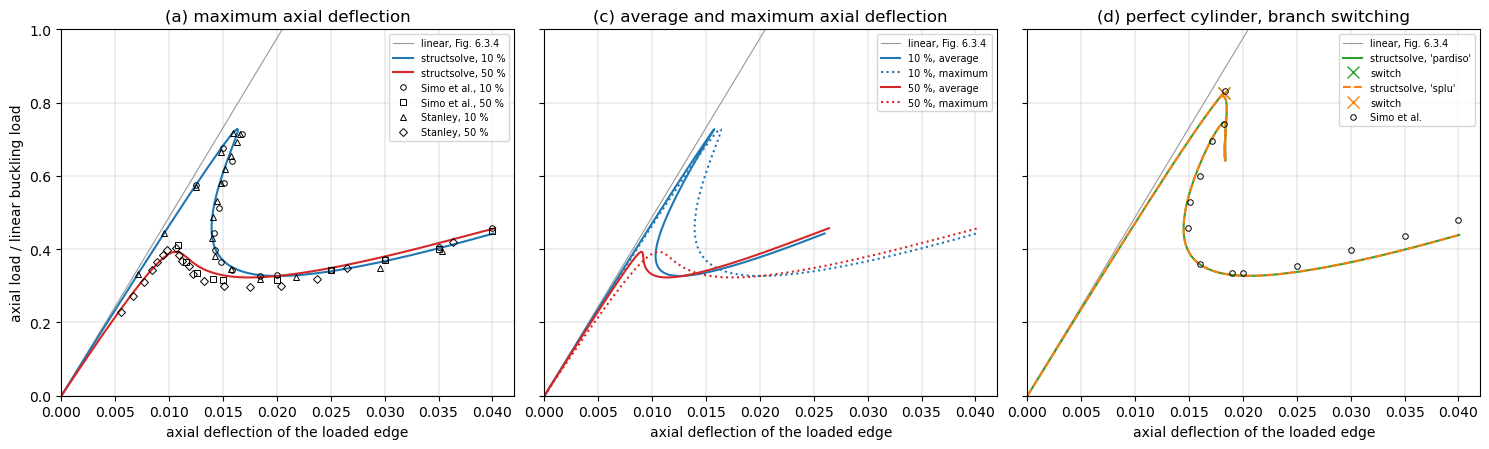

In [6]:
fig, axes = plt.subplots(1, 3, figsize=(15, 4.6), sharey=True)
ulin = np.array([0, 0.04])
for ax in axes:
    ax.plot(ulin, ulin/su.FIG_LINEAR_U1, color='0.6', lw=0.8, label='linear, Fig. 6.3.4')
ax = axes[0]
for key, color in (('10 %', 'C0'), ('50 %', 'C3')):
    ax.plot(res[key]['u_max'], res[key]['lbds0'], color=color, label='structsolve, %s' % key)
for data, mk, lab in ((su.FIG_A_SIMO_10, 'o', 'Simo et al., 10 %'), (su.FIG_A_SIMO_50, 's', 'Simo et al., 50 %'),
                      (su.FIG_A_ANS_10, '^', 'Stanley, 10 %'), (su.FIG_A_ANS_50, 'D', 'Stanley, 50 %')):
    d = np.array(data)
    ax.plot(d[:, 0], d[:, 1], mk, ms=4, mfc='none', color='k', mew=0.7, label=lab)
ax.set_title('(a) maximum axial deflection')
ax.set_ylabel('axial load / linear buckling load')
ax = axes[1]
for key, color in (('10 %', 'C0'), ('50 %', 'C3')):
    ax.plot(res[key]['u_avg'], res[key]['lbds0'], color=color, label='%s, average' % key)
    ax.plot(res[key]['u_max'], res[key]['lbds0'], color=color, ls=':', label='%s, maximum' % key)
ax.set_title('(c) average and maximum axial deflection')
ax = axes[2]
for key, color, ls in (('perfect, pardiso', 'C2', '-'), ('perfect, splu', 'C1', '--')):
    r = res[key]
    ax.plot(r['u_max'], r['lbds0'], color=color, ls=ls, label="structsolve, '%s'" % key.split(', ')[1])
    bp = r['branch_points'] + 1
    ax.plot(r['u_max'][bp], r['lbds0'][bp], 'x', color=color, ms=8, label='switch')
d = np.array(su.FIG_D_SIMO)
ax.plot(d[:, 0], d[:, 1], 'o', ms=4, mfc='none', color='k', mew=0.7, label='Simo et al.')
ax.set_title('(d) perfect cylinder, branch switching')
for ax in axes:
    ax.set_xlim(0, 0.042)
    ax.set_ylim(0, 1)
    ax.set_xlabel('axial deflection of the loaded edge')
    ax.grid(lw=0.3)
    ax.legend(fontsize=7, loc='upper right')
plt.tight_layout()
plt.show()

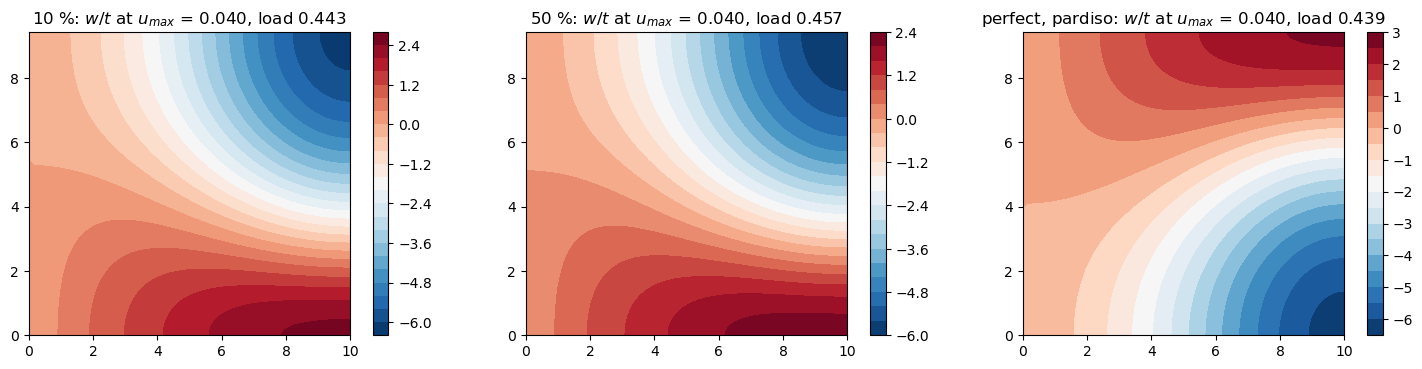

In [7]:
fig, axes = plt.subplots(1, 3, figsize=(15, 3.6))
for ax, key in zip(axes, ('10 %', '50 %', 'perfect, pardiso')):
    r = res[key]
    r['s'].uvw(r['cs'][-1], gridx=60, gridy=60)
    cf = ax.contourf(r['s'].plot_mesh['Xs'], r['s'].plot_mesh['Ys'], r['s'].fields['w']/su.t, levels=21, cmap='RdBu_r')
    ax.set_aspect('equal')
    ax.set_title('%s: $w/t$ at $u_{max}$ = %.3f, load %.3f' % (key, r['u'][-1, 1], r['lbds'][-1]))
    plt.colorbar(cf, ax=ax)
plt.tight_layout()
plt.show()

## Discussion

- **Imperfect cylinders.** The Riks method passes the limit points and the snap-back of the 10 % imperfection, where both the load and the deflection decrease, and follows the post-buckling plateau to an axial deflection twice that of the linear buckling load, with $\max|w|$ about 6 $t$, every increment in equilibrium to $10^{-9}$ of the load. The limit loads are within 0.013 (10 %) and 0.018 (50 %) of those read for Simo et al. and within 0.011 and 0.009 of Stanley's, the deflections at them within 0.0005; the snap-back, back to $u_{max}$ = 0.0139 (0.0142 read), and the plateau at 0.32 to 0.33 are those of the figure, and from $u_{max}$ = 0.025 to 0.04 the loads are within 0.02 of Simo et al. Fig. (c): the average deflection of the post-buckled edge is much smaller than the maximum one, as in the figure.
- **Perfect cylinder.** With both linear solvers the switch is made at the load 0.827, where a dense eigenvalue analysis of the tangent stiffness matrix has its first negative eigenvalue, 18 % below the linear buckling load because of the non-linear axisymmetric prebuckling of the radially restrained loaded edge, and within 0.006 of the bifurcation of Simo et al. (0.833), as is the deflection at it. The paths of `'pardiso'` and `'splu'` are the same: the bifurcated branch snaps back to $u_{max}$ = 0.0145 at the load 0.453 (0.0149 at 0.457 in the figure) and reaches the plateau at 0.327 (0.333). Beyond $u_{max}$ = 0.025 the loads are 0.02 to 0.04 below those of Simo et al., whose curve is, as they say, the envelope of several paths followed after switches between branches, while a single switch is made here: their curve ends above those of the imperfect cylinders, the computed one just below them.
- **Linear prebuckling line.** The straight line of the figures reaches the load 1 at an axial deflection of 0.0205 (read), the linear solution here at 0.0210: the abscissae of the figure are the shortening of the $L/10$ section, the 2 % difference coming from the normalizing buckling load or the prebuckling stiffness of the finite elements of Simo et al.
- **Ritz terms.** With $10 \times 10$ to $14 \times 14$ terms the limit loads, the minimum loads and the loads at $u_{max}$ = 0.04 change by less than 0.003 and do not change in the third digit from $10 \times 10$ on, for the perfect cylinder as well (switch at 0.8270 and 0.8267 with $10 \times 10$ and $12 \times 12$ terms, with both linear solvers); see [Post-buckling of an axially compressed cylinder](ex_cylinder_postbuckling.ipynb).

### Branch switching and the linear solvers in this benchmark

- **The critical eigenvector.** At a bifurcation `arc_length._critical_eigenvector` computes, by a subspace iteration with the available factorization, the eigenvalues of the tangent stiffness matrix closest to zero, enough of them to hold the negative eigenvalues counted by the factorization: the subspace starts with at least `num_neg + 2` vectors and doubles, up to 64 vectors, while fewer Ritz values than counted are negative. This matters here: weakly stiff in-plane Ritz terms have positive eigenvalues closer to zero than the negative ones, about $1.5 \times 10^{-4}$ along the whole path in the scaled unknowns with $8 \times 8$ terms, and $1.8 \times 10^{-5}$ and $3.3 \times 10^{-6}$ with $10 \times 10$ and $12 \times 12$ terms; a subspace holding only them gives an eigenvector that is not the critical one, and the switch converges back on the fundamental path. With `'splu'`, which has no count of negative eigenvalues, one negative eigenvalue is looked for when the determinant is negative.
- **PARDISO with perturbed pivots.** With its default parameters PARDISO perturbs 18 to 20 pivots of these dense tangent stiffness matrices, which makes the count of negative eigenvalues uncertain (one short from the load 0.827 to 0.893, such that the first critical point would be found at 0.90 instead of 0.83). [static._factorize](../static.rst) factorizes such a matrix again with `iparm(24) = 1`, the two-level factorization, which perturbs no pivot here: the counts are then those of the dense eigenvalue analysis at every increment. This second factorization is why the run with `'pardiso'` takes longer than that with `'splu'` for this small, dense model.